In [37]:
import pandas as pd
df = pd.read_csv(
    "/content/drive/MyDrive/Project/Amazon-Products.csv"
)
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nNumber of unique main categories:")
print(df["main_category"].nunique())

print("\nProducts in each main category:")
print(df["main_category"].value_counts())

Dataset shape: (551585, 10)

Column names:
['Unnamed: 0', 'name', 'main_category', 'sub_category', 'image', 'link', 'ratings', 'no_of_ratings', 'discount_price', 'actual_price']

Number of unique main categories:
20

Products in each main category:
main_category
accessories                116141
men's clothing              76656
women's clothing            76512
tv, audio & cameras         68659
men's shoes                 57456
appliances                  33096
stores                      32903
home & kitchen              14568
kids' fashion               13488
sports & fitness            12648
bags & luggage              10416
beauty & health             10122
car & motorbike              7080
toys & baby products         6216
women's shoes                5472
industrial supplies          4104
grocery & gourmet foods      3312
pet supplies                 1632
music                        1080
home, kitchen, pets            24
Name: count, dtype: int64


In [38]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nNumber of unique product names:")
print(df["name"].nunique())

print("\nNumber of unique product links:")
print(df["link"].nunique())

Missing values in each column:
Unnamed: 0             0
name                   0
main_category          0
sub_category           0
image                  0
link                   0
ratings           175794
no_of_ratings     175794
discount_price     61163
actual_price       17813
dtype: int64

Number of duplicate rows:
0

Number of unique product names:
396210

Number of unique product links:
551585


In [39]:
TARGET_PRODUCT_COUNT = 10000
MAX_PRODUCTS_PER_CATEGORY = 500

category_samples = []

for category, group in df.groupby("main_category"):
    sample_size = min(MAX_PRODUCTS_PER_CATEGORY, len(group))

    category_samples.append(
        group.sample(n=sample_size, random_state=42)
    )


category_sample = pd.concat(category_samples)

# Find the remaining products
remaining_products = df.drop(index=category_sample.index)

# Select additional products to reach 10,000
additional_count = TARGET_PRODUCT_COUNT - len(category_sample)

additional_products = remaining_products.sample(
    n=additional_count,
    random_state=42
)

# Combine all selected products
products = pd.concat(
    [category_sample, additional_products],
    ignore_index=True
)

# Shuffle the products
products = products.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Verify the result
print("Original dataset shape:", df.shape)
print("Selected products shape:", products.shape)

display(products.head())

Original dataset shape: (551585, 10)
Selected products shape: (10000, 10)


,Unnamed: 0,name,main_category,sub_category,image,link,ratings,no_of_ratings,discount_price,actual_price
0,462,PEDIGREE Biscrok Biscuits Dog Treats Chicken F...,pet supplies,All Pet Supplies,https://m.media-amazon.com/images/I/61XOAg-Eg9...,https://www.amazon.in/PEDIGREE-Biscrok-Biscuit...,4.5,2,NaN,NaN
1,7849,Jack & Jones Men Jeans,men's clothing,Jeans,https://m.media-amazon.com/images/W/IMAGERENDE...,https://www.amazon.in/Jack-Jones-139437701-Lig...,NaN,NaN,NaN,"₹3,999"
2,674,KN Mall Ladies Curly Hair Machine Curl Secret ...,beauty & health,Personal Care Appliances,https://m.media-amazon.com/images/W/IMAGERENDE...,https://www.amazon.in/KN-Machine-Revolutionary...,NaN,NaN,"₹1,449","₹2,449"
3,6266,Macho Men's Cotton Brief/Underwear Multicolor ...,men's clothing,Innerwear,https://m.media-amazon.com/images/I/712xi+V9Gw...,https://www.amazon.in/Macho-Smart-Cotton-Brief...,4.1,58,₹470,₹699
4,139,"TRASE Unisex Baby & Kids Sandals | Soft, Comfo...",kids' fashion,Kids' Fashion,https://m.media-amazon.com/images/I/71OuDuEQl2...,https://www.amazon.in/TRASE-88-018-Blue-Unisex...,3.9,418,₹359,₹599


In [40]:
print("Missing values in selected products:")
print(products.isnull().sum())

print("\nProducts in each category:")
print(products["main_category"].value_counts())

Missing values in selected products:
Unnamed: 0           0
name                 0
main_category        0
sub_category         0
image                0
link                 0
ratings           2702
no_of_ratings     2702
discount_price    1203
actual_price       268
dtype: int64

Products in each category:
main_category
accessories                594
women's clothing           567
men's clothing             566
tv, audio & cameras        562
men's shoes                561
stores                     530
appliances                 526
bags & luggage             512
sports & fitness           511
home & kitchen             510
kids' fashion              509
car & motorbike            508
grocery & gourmet foods    505
beauty & health            504
toys & baby products       504
women's shoes              504
industrial supplies        502
pet supplies               501
music                      500
home, kitchen, pets         24
Name: count, dtype: int64


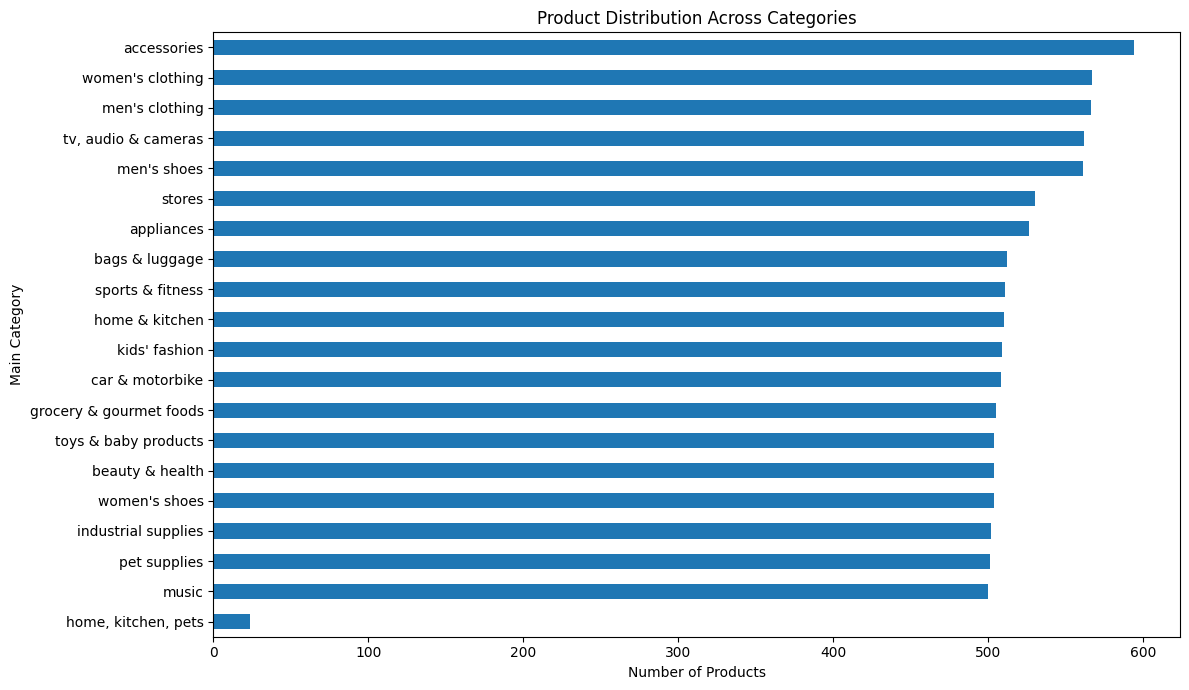

In [41]:
import matplotlib.pyplot as plt

category_counts = products["main_category"].value_counts()

plt.figure(figsize=(12, 7))
category_counts.sort_values().plot(kind="barh")

plt.title("Product Distribution Across Categories")
plt.xlabel("Number of Products")
plt.ylabel("Main Category")

plt.tight_layout()
plt.show()

Products with available ratings: 7130
Average rating: 3.88
Median rating: 4.0
Minimum rating: 1.0
Maximum rating: 5.0


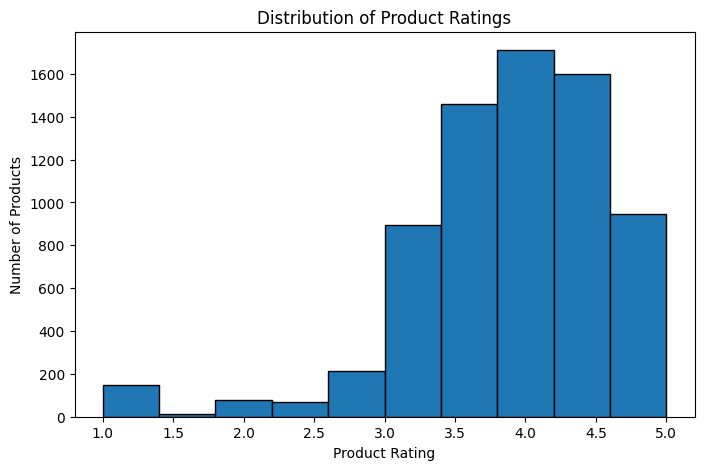

In [42]:
valid_ratings = pd.to_numeric(
    products["ratings"],
    errors="coerce"
).dropna()

print("Products with available ratings:",len(valid_ratings))
print("Average rating:",round(valid_ratings.mean(),2))
print("Median rating:", round(valid_ratings.median(), 2))
print("Minimum rating:", valid_ratings.min())
print("Maximum rating:", valid_ratings.max())

plt.figure(figsize=(8,5))
plt.hist(valid_ratings,bins=10,edgecolor="black")

plt.title("Distribution of Product Ratings")
plt.xlabel("Product Rating")
plt.ylabel("Number of Products")

plt.show()

In [43]:
discount_prices = pd.to_numeric(
    products["discount_price"]
    .str.replace("₹", "")
    .str.replace(",", ""),
    errors="coerce"
).dropna()

actual_prices = pd.to_numeric(
    products["actual_price"]
    .str.replace("₹", "")
    .str.replace(",", ""),
    errors="coerce"
).dropna()

print("Discounted price statistics:")
print("Available prices:", len(discount_prices))
print("Average price:", round(discount_prices.mean(), 2))
print("Median price:", round(discount_prices.median(), 2))
print("Minimum price:", discount_prices.min())
print("Maximum price:", discount_prices.max())


print("\nActual price statistics:")
print("Available prices:", len(actual_prices))
print("Average price:", round(actual_prices.mean(), 2))
print("Median price:", round(actual_prices.median(), 2))
print("Minimum price:", actual_prices.min())
print("Maximum price:", actual_prices.max())

Discounted price statistics:
Available prices: 8797
Average price: 2033.84
Median price: 599.0
Minimum price: 20.0
Maximum price: 1249990.0

Actual price statistics:
Available prices: 9732
Average price: 3518.09
Median price: 1249.0
Minimum price: 20.0
Maximum price: 1594900.0


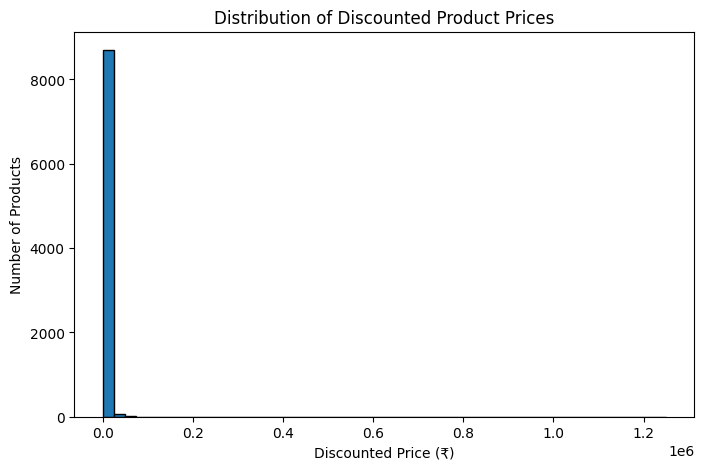

In [44]:
plt.figure(figsize=(8, 5))

plt.hist(discount_prices, bins=50, edgecolor="black")

plt.title("Distribution of Discounted Product Prices")
plt.xlabel("Discounted Price (₹)")
plt.ylabel("Number of Products")

plt.show()

In [45]:
products["product_features"] = (
    products["name"].str.lower() + " " +
    products["main_category"].str.lower() + " " +
    products["sub_category"].str.lower()
)

display(
    products[[
        "name",
        "main_category",
        "sub_category",
        "product_features"
    ]].head()
)

,name,main_category,sub_category,product_features
0,PEDIGREE Biscrok Biscuits Dog Treats Chicken F...,pet supplies,All Pet Supplies,pedigree biscrok biscuits dog treats chicken f...
1,Jack & Jones Men Jeans,men's clothing,Jeans,jack & jones men jeans men's clothing jeans
2,KN Mall Ladies Curly Hair Machine Curl Secret ...,beauty & health,Personal Care Appliances,kn mall ladies curly hair machine curl secret ...
3,Macho Men's Cotton Brief/Underwear Multicolor ...,men's clothing,Innerwear,macho men's cotton brief/underwear multicolor ...
4,"TRASE Unisex Baby & Kids Sandals | Soft, Comfo...",kids' fashion,Kids' Fashion,"trase unisex baby & kids sandals | soft, comfo..."


In [46]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(stop_words="english")

tfidf_matrix = tfidf_vectorizer.fit_transform(
    products["product_features"]
)

print("Number of products:", tfidf_matrix.shape[0])
print("Number of features:", tfidf_matrix.shape[1])
print("TF-IDF matrix shape:", tfidf_matrix.shape)

print("\nSample features:")
print(tfidf_vectorizer.get_feature_names_out()[:20])

Number of products: 10000
Number of features: 19346
TF-IDF matrix shape: (10000, 19346)

Sample features:
['00' '000' '0000' '00005' '00007' '0001' '000100' '0005p' '001' '001g'
 '001mm' '001x12' '002' '003' '004' '004grn' '004mar' '005' '0051' '006']


In [47]:
from sklearn.neighbors import NearestNeighbors
NUMBER_OF_RECOMMENDATIONS=10

knn_model = NearestNeighbors(
    n_neighbors=NUMBER_OF_RECOMMENDATIONS + 1,
    metric="cosine",
    algorithm = "brute"

)

knn_model.fit(tfidf_matrix)



NearestNeighbors(algorithm='brute', metric='cosine', n_neighbors=11)

In [48]:

# Model 1: Nearest Neighbors recommendation function

NUMBER_OF_CANDIDATES = 50
NUMBER_OF_RECOMMENDATIONS = 10

def get_knn_recommendations(selected_product_index):

    selected_product = products.loc[selected_product_index]
    selected_features = tfidf_matrix[selected_product_index]

    distances, indices = knn_model.kneighbors(
        selected_features,
        n_neighbors=min(NUMBER_OF_CANDIDATES, len(products))
    )

    recommendation_records = []

    seen_product_names = {
        str(selected_product["name"]).strip().casefold()
    }

    for distance, product_index in zip(
        distances.flatten(),
        indices.flatten()
    ):
        recommended_product = products.iloc[product_index]

        product_name = str(
            recommended_product["name"]
        ).strip().casefold()

        # Skip duplicate product names, including the selected product
        if product_name in seen_product_names:
            continue

        seen_product_names.add(product_name)

        recommendation_records.append({
            "name": recommended_product["name"],
            "main_category": recommended_product["main_category"],
            "sub_category": recommended_product["sub_category"],
            "similarity_score": round(1 - float(distance), 4)
        })

        if len(recommendation_records) == NUMBER_OF_RECOMMENDATIONS:
            break

    return pd.DataFrame(recommendation_records)


In [49]:
# Demonstrate Model 1: Nearest Neighbors

selected_product_index = 0

print("Selected product:")
display(
    products.iloc[[selected_product_index]][
        ["name", "main_category", "sub_category"]
    ]
)

print("\nRecommended products:")
display(get_knn_recommendations(selected_product_index))

Selected product:


,name,main_category,sub_category
0,PEDIGREE Biscrok Biscuits Dog Treats Chicken F...,pet supplies,All Pet Supplies



Recommended products:


,name,main_category,sub_category,similarity_score
0,Pedigree Biscrok Biscuits Dog Treats (Above 4 ...,pet supplies,Dog supplies,0.6468
1,Petfun Chicken Flavored Adult Dog Biscuit 1 kg...,pet supplies,Dog supplies,0.5847
2,"Smart Heart Adult Dog Food Dry Power Pack, Chi...",pet supplies,All Pet Supplies,0.5699
3,"Pedigree Puppy Dry Dog Food, Chicken & Milk, 1...",pet supplies,All Pet Supplies,0.5673
4,UNIK Dog Pet Food Calcium Treat Healthy Chicke...,pet supplies,Dog supplies,0.5439
5,"Purepet Chicken and Milk Adult Dry Dog Food, 1...",pet supplies,All Pet Supplies,0.5150
6,Tunai Super Saver Dog Biscuits | Dog Treats | ...,pet supplies,Dog supplies,0.4840
7,"SUPERCOAT Adult Dry Dog Food, Chicken- 10Kg Pack",pet supplies,Dog supplies,0.4804
8,"MUNCHOS Dog Biscuits, Chicken Flavor, 500gm Jar",pet supplies,Dog supplies,0.4618
9,Fidele+ Dry Dog Food Adult Large Breed Chicken...,pet supplies,Dog supplies,0.4572


In [50]:
###2nd MODEL ---- Kmeans

In [51]:
from sklearn.cluster import KMeans


NUMBER_OF_CLUSTERS = 20


kmeans_model = KMeans(
    n_clusters=NUMBER_OF_CLUSTERS,
    random_state=42,
    n_init=10
)


product_cluster_labels = kmeans_model.fit_predict(
    tfidf_matrix
)


products["cluster"] = product_cluster_labels


print("K-Means model fitted successfully.")
print("Total products:", len(products))
print("Number of clusters:", products["cluster"].nunique())

print("\nProducts in each cluster:")
print(products["cluster"].value_counts().sort_index())

K-Means model fitted successfully.
Total products: 10000
Number of clusters: 20

Products in each cluster:
cluster
0     505
1     463
2     765
3     560
4     406
5     510
6     501
7     530
8     528
9     285
10    500
11    577
12    523
13    504
14    603
15    156
16    512
17    496
18    574
19    502
Name: count, dtype: int64


In [52]:

for cluster_number in range(NUMBER_OF_CLUSTERS):


    cluster_products = products[
        products["cluster"] == cluster_number
    ]

    print(f"\nCluster {cluster_number}")
    print("Number of products:", len(cluster_products))


    print("\nTop product categories:")
    print(
        cluster_products["main_category"]
        .value_counts()
        .head(3)
    )


    print("\nExample products:")
    display(
        cluster_products[
            ["name", "main_category", "sub_category"]
        ].head(5)
    )


Cluster 0
Number of products: 505

Top product categories:
main_category
grocery & gourmet foods    505
Name: count, dtype: int64

Example products:


,name,main_category,sub_category
10,"Too Yumm Karare Noodle Masala, 75g",grocery & gourmet foods,All Grocery & Gourmet Foods
31,Flyberry Gourmet Medjoul/Mejdool Dates 1kg | J...,grocery & gourmet foods,All Grocery & Gourmet Foods
58,SKYBEAN Cappuccino + Hazelnut + Mocha Coffee C...,grocery & gourmet foods,"Coffee, Tea & Beverages"
59,"Fruitbell Fruit Crush- Litchi, 1000ml",grocery & gourmet foods,"Coffee, Tea & Beverages"
66,"Qua Natural Mineral Water, 1 l, Pack of 12",grocery & gourmet foods,"Coffee, Tea & Beverages"



Cluster 1
Number of products: 463

Top product categories:
main_category
kids' fashion       461
sports & fitness      2
Name: count, dtype: int64

Example products:


,name,main_category,sub_category
4,"TRASE Unisex Baby & Kids Sandals | Soft, Comfo...",kids' fashion,Kids' Fashion
115,Adrianna by Khadim's Pink Sneaker for Girls,kids' fashion,Kids' Shoes
119,Fashion Vegan artificial Leather Backpack Purs...,kids' fashion,School Bags
121,Casio Youth Digital Grey Dial Men's Watch-AE-1...,kids' fashion,Kids' Watches
127,WORLD WEAR FOOTWEAR Kids & Boys (Combo-(2)-926...,kids' fashion,Kids' Shoes



Cluster 2
Number of products: 765

Top product categories:
main_category
bags & luggage    511
accessories       220
kids' fashion      31
Name: count, dtype: int64

Example products:


...

,name,main_category,sub_category
23,Latest Women sandals Black Plain_5,women's shoes,Fashion Sandals
44,Flat Max- (PVFM-001) Ideal for Flats in Housin...,women's shoes,Ballerinas
80,"North Star Women Break Sneakers, White, (5511133)",women's shoes,Shoes
92,Planet Wear Girl Kids Antique Golden SuperStar...,women's shoes,Ballerinas
96,BATA Women GRACEN BLACK Heels,women's shoes,Fashion Sandals



Cluster 18
Number of products: 574

Top product categories:
main_category
men's shoes         561
women's shoes         9
sports & fitness      2
Name: count, dtype: int64

Example products:


,name,main_category,sub_category
7,Cocus Pavoo Boy's Badminton Shoes (9 IND/UK) Blue,men's shoes,Sports Shoes
12,Paris Plus Formal Shoes for Men 4411_BL,men's shoes,Formal Shoes
17,Camfoot Men's Casual Clogs,men's shoes,Casual Shoes
70,ANDUNE Men's Barefoot & Minimalist Cross Train...,men's shoes,Sports Shoes
82,INLAZER Trendy Designer Height Increasing Shoe...,men's shoes,Formal Shoes



Cluster 19
Number of products: 502

Top product categories:
main_category
industrial supplies    502
Name: count, dtype: int64

Example products:


,name,main_category,sub_category
14,ISO PROPYL ALCOHOL LR - 250ml (IPA) (Propan-2-...,industrial supplies,Lab & Scientific
38,Easy Electronics DS18B20 Temperature Sensor - ...,industrial supplies,"Test, Measure & Inspect"
50,Scotch-Brite No-Dust Fiber Broom (Multi-Purpos...,industrial supplies,Janitorial & Sanitation Supplies
72,Cleaning Brush Aluminium Kitchen Basin Gas Sto...,industrial supplies,Industrial & Scientific Supplies
83,"SIMBA 12"" Black Finish Bathroom Basin Mixer Lu...",industrial supplies,Janitorial & Sanitation Supplies


In [53]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity


# Model 2: K-Means + Cosine Similarity
def get_kmeans_recommendations(selected_product_index):

    selected_product = products.iloc[selected_product_index]
    selected_cluster = selected_product["cluster"]

    cluster_product_indices = products.index[
        products["cluster"] == selected_cluster
    ].to_numpy()

    similarity_scores = cosine_similarity(
        tfidf_matrix[selected_product_index],
        tfidf_matrix[cluster_product_indices]
    ).flatten()

    candidate_order = np.argsort(similarity_scores)[::-1]

    selected_name = str(selected_product["name"]).strip().casefold()
    seen_names = {selected_name}
    recommendation_records = []

    for candidate_position in candidate_order:

        candidate_index = int(
            cluster_product_indices[candidate_position]
        )
        candidate = products.iloc[candidate_index]
        candidate_name = str(candidate["name"]).strip().casefold()

        if candidate_index == selected_product_index:
            continue

        if candidate_name in seen_names:
            continue

        recommendation_records.append({
            "name": candidate["name"],
            "main_category": candidate["main_category"],
            "sub_category": candidate["sub_category"],
            "similarity_score": round(
                float(similarity_scores[candidate_position]), 3
            )
        })

        seen_names.add(candidate_name)

        if len(recommendation_records) == NUMBER_OF_RECOMMENDATIONS:
            break

    return pd.DataFrame(recommendation_records)


# Select five products from five different categories
test_categories = products["main_category"].drop_duplicates().head(5)

for category in test_categories:

    selected_product_index = int(
        products.index[products["main_category"] == category][0]
    )

    selected_product = products.iloc[selected_product_index]
    print("TEST CATEGORY:", category)
    print("SELECTED PRODUCT:", selected_product["name"])

    print("\nMODEL 1: TF-IDF + NEAREST NEIGHBORS")
    display(get_knn_recommendations(selected_product_index))

    print("\nMODEL 2: K-MEANS + COSINE SIMILARITY")
    display(get_kmeans_recommendations(selected_product_index))


TEST CATEGORY: pet supplies
SELECTED PRODUCT: PEDIGREE Biscrok Biscuits Dog Treats Chicken Flavor, 500g Pack of 2 Chicken 1 kg (2x0.5 kg) Dry Adult, Young, Senior Dog Food

MODEL 1: TF-IDF + NEAREST NEIGHBORS


,name,main_category,sub_category,similarity_score
0,Pedigree Biscrok Biscuits Dog Treats (Above 4 ...,pet supplies,Dog supplies,0.6468
1,Petfun Chicken Flavored Adult Dog Biscuit 1 kg...,pet supplies,Dog supplies,0.5847
2,"Smart Heart Adult Dog Food Dry Power Pack, Chi...",pet supplies,All Pet Supplies,0.5699
3,"Pedigree Puppy Dry Dog Food, Chicken & Milk, 1...",pet supplies,All Pet Supplies,0.5673
4,UNIK Dog Pet Food Calcium Treat Healthy Chicke...,pet supplies,Dog supplies,0.5439
5,"Purepet Chicken and Milk Adult Dry Dog Food, 1...",pet supplies,All Pet Supplies,0.5150
6,Tunai Super Saver Dog Biscuits | Dog Treats | ...,pet supplies,Dog supplies,0.4840
7,"SUPERCOAT Adult Dry Dog Food, Chicken- 10Kg Pack",pet supplies,Dog supplies,0.4804
8,"MUNCHOS Dog Biscuits, Chicken Flavor, 500gm Jar",pet supplies,Dog supplies,0.4618
9,Fidele+ Dry Dog Food Adult Large Breed Chicken...,pet supplies,Dog supplies,0.4572



MODEL 2: K-MEANS + COSINE SIMILARITY


,name,main_category,sub_category,similarity_score
0,Pedigree Biscrok Biscuits Dog Treats (Above 4 ...,pet supplies,Dog supplies,0.647
1,Petfun Chicken Flavored Adult Dog Biscuit 1 kg...,pet supplies,Dog supplies,0.585
2,"Smart Heart Adult Dog Food Dry Power Pack, Chi...",pet supplies,All Pet Supplies,0.570
3,"Pedigree Puppy Dry Dog Food, Chicken & Milk, 1...",pet supplies,All Pet Supplies,0.567
4,UNIK Dog Pet Food Calcium Treat Healthy Chicke...,pet supplies,Dog supplies,0.544
5,"Purepet Chicken and Milk Adult Dry Dog Food, 1...",pet supplies,All Pet Supplies,0.515
6,Tunai Super Saver Dog Biscuits | Dog Treats | ...,pet supplies,Dog supplies,0.484
7,"SUPERCOAT Adult Dry Dog Food, Chicken- 10Kg Pack",pet supplies,Dog supplies,0.480
8,"MUNCHOS Dog Biscuits, Chicken Flavor, 500gm Jar",pet supplies,Dog supplies,0.462
9,Fidele+ Dry Dog Food Adult Large Breed Chicken...,pet supplies,Dog supplies,0.457


TEST CATEGORY: men's clothing
SELECTED PRODUCT: Jack & Jones Men Jeans

MODEL 1: TF-IDF + NEAREST NEIGHBORS


...

,name,main_category,sub_category,similarity_score
0,TRASE FS-II Comfortable Outdoor Kids Boys Snea...,kids' fashion,Kids' Shoes,0.553
1,AaoJao Comfortable and soft Unisex Kids Shoe f...,kids' fashion,Kids' Shoes,0.501
2,toothless Barbie Kids Girls Pink Fashion Sandals,kids' fashion,Kids' Shoes,0.463
3,Baby's Pride Boys and Girls Unisex Kids Nightsuit,kids' fashion,Kids' Fashion,0.433
4,Max Girls Top,kids' fashion,Kids' Fashion,0.426
5,Cotton Kurta Pajama Set for Boys Kids,kids' fashion,Kids' Fashion,0.398
6,NEW GEN Baby Casual WEAR,kids' fashion,Kids' Clothing,0.393
7,Stepee baby kids sandal for girls,kids' fashion,Baby Fashion,0.390
8,TICOSS Kids Boys and Girls Super Soft Cotton T...,kids' fashion,Kids' Fashion,0.381
9,A V Shop Double Frozen Glitter Girls Sliders|S...,kids' fashion,Kids' Shoes,0.378


TEST CATEGORY: appliances
SELECTED PRODUCT: SPS MPPT Solar Hybrid Inverter HS 1500-A-12V

MODEL 1: TF-IDF + NEAREST NEIGHBORS


,name,main_category,sub_category,similarity_score
0,"Prestige 1.5 Litre Kettle 1500-watts, Red",appliances,Kitchen & Home Appliances,0.3005
1,Solar Cleano Solar Panel Cleaner (1 Liter),home & kitchen,Garden & Outdoors,0.2282
2,Havells Solace 1500 Watt with PTC Ceramic Heat...,appliances,Kitchen & Home Appliances,0.2081
3,Kit4Curious 12v Solar/DC to AC Converter with ...,car & motorbike,All Car & Motorbike Products,0.2061
4,V-Guard VKP15 Prime 1.5 Litre Electric Kettle ...,appliances,Kitchen & Home Appliances,0.2017
5,"Uphar Immersion Rod 1500 Watts, Water Heater -...",appliances,Heating & Cooling Appliances,0.1988
6,Russell Hobbs 18790 1250/1500 Watt Premium Sta...,appliances,Kitchen & Home Appliances,0.1864
7,RO Protection Cover for Aquaguard Enhance,appliances,Kitchen & Home Appliances,0.1838
8,AmazonBasics 1.5 Ton 5 Star Inverter Split AC ...,appliances,Heating & Cooling Appliances,0.1803
9,Kenstar JETT HC 51 Personal Desert Air Water C...,appliances,Kitchen & Home Appliances,0.1790



MODEL 2: K-MEANS + COSINE SIMILARITY


,name,main_category,sub_category,similarity_score
0,"Prestige 1.5 Litre Kettle 1500-watts, Red",appliances,Kitchen & Home Appliances,0.300
1,Havells Solace 1500 Watt with PTC Ceramic Heat...,appliances,Kitchen & Home Appliances,0.208
2,V-Guard VKP15 Prime 1.5 Litre Electric Kettle ...,appliances,Kitchen & Home Appliances,0.202
3,"Uphar Immersion Rod 1500 Watts, Water Heater -...",appliances,Heating & Cooling Appliances,0.199
4,Russell Hobbs 18790 1250/1500 Watt Premium Sta...,appliances,Kitchen & Home Appliances,0.186
5,RO Protection Cover for Aquaguard Enhance,appliances,Kitchen & Home Appliances,0.184
6,AmazonBasics 1.5 Ton 5 Star Inverter Split AC ...,appliances,Heating & Cooling Appliances,0.180
7,Kenstar JETT HC 51 Personal Desert Air Water C...,appliances,Kitchen & Home Appliances,0.179
8,CHAIN PULLEY BLOCK 1 TON 6 MTR,appliances,Kitchen & Home Appliances,0.177
9,COCS Premium Steel Puttu Maker.,appliances,Kitchen & Home Appliances,0.176


In [54]:

NUMBER_OF_TEST_PRODUCTS = 100

test_product_indices = (
    products.sample(
        n=NUMBER_OF_TEST_PRODUCTS,
        random_state=42
    ).index
)

evaluation_records = []

models_to_evaluate = [
    ("Model 1 - Nearest Neighbors", get_knn_recommendations),
    ("Model 2 - K-Means", get_kmeans_recommendations)
]

for product_index in test_product_indices:

    selected_product = products.iloc[product_index]

    for model_name, recommendation_function in models_to_evaluate:

        recommendations = recommendation_function(product_index)

        if recommendations.empty:
            continue

        main_category_match = (
            recommendations["main_category"]
            == selected_product["main_category"]
        ).mean() * 100

        sub_category_match = (
            recommendations["sub_category"]
            == selected_product["sub_category"]
        ).mean() * 100

        evaluation_records.append({
            "product_index": product_index,
            "model": model_name,
            "main_category_match_percent": main_category_match,
            "sub_category_match_percent": sub_category_match
        })

evaluation_results = pd.DataFrame(evaluation_records)

model_comparison = (
    evaluation_results
    .groupby("model")
    .agg(
        tested_products=("product_index", "nunique"),
        average_main_category_match=(
            "main_category_match_percent", "mean"
        ),
        average_sub_category_match=(
            "sub_category_match_percent", "mean"
        )
    )
    .round(2)
    .reset_index()
)

display(model_comparison)


,model,tested_products,average_main_category_match,average_sub_category_match
0,Model 1 - Nearest Neighbors,100,89.5,75.7
1,Model 2 - K-Means,100,95.7,79.6


**Model Building and Training – Project Progress Update**

**Project:** ML-Based E-Commerce Product Recommendation Web Application Using FastAPI

- Selected and analyzed the Amazon Products dataset containing 551,585 records.
- Prepared a working dataset of 10,000 products using category-based sampling.
- Performed EDA, including missing-value analysis, product category analysis, and rating and price analysis.
- Applied TF-IDF vectorization to product names, main categories, and subcategories to convert product text into numerical features.
- Implemented two recommendation approaches:
  1. **Model 1 – Nearest Neighbors:** Uses cosine distance to identify similar products.
  2. **Model 2 – K-Means:** Groups products into 20 clusters and recommends similar products within the same cluster.
- Evaluated both models using 100 test products based on category consistency.

**Evaluation Results:**

| Metric | Nearest Neighbors | K-Means |
|---|---:|---:|
| Main-category match | 89.5% | 95.7% |
| Subcategory match | 75.7% | 79.6% |

**Current status:** Both recommendation approaches are implemented and evaluated. K-Means achieved higher category-match percentages in the current evaluation.
